In [ ]:
# Clone the repo
# !git clone --recursive https://github.com/microsoft/BitNet.git


# %cd BitNet
# !pip install -qq -r requirements.txt

# %cd gpu
# !pip install -qq -r requirements.txt

# !pip install -qq --upgrade torch torchvision torchaudio

!pip install bitblas -qq

Cloning into 'BitNet'...
remote: Enumerating objects: 432, done.
remote: Total 432 (delta 0), reused 0 (delta 0), pack-reused 432 (from 1)
Receiving objects: 100% (432/432), 8.12 MiB | 32.98 MiB/s, done.
Resolving deltas: 100% (196/196), done.
Submodule '3rdparty/llama.cpp' (https://github.com/Eddie-Wang1120/llama.cpp.git) registered for path '3rdparty/llama.cpp'
Cloning into '/content/BitNet/3rdparty/llama.cpp'...
remote: Enumerating objects: 25639, done.        
remote: Total 25639 (delta 0), reused 0 (delta 0), pack-reused 25639 (from 1)        
Receiving objects: 100% (25639/25639), 59.72 MiB | 30.18 MiB/s, done.
Resolving deltas: 100% (18204/18204), done.
Submodule path '3rdparty/llama.cpp': checked out '1f86f058de0c3f4098dedae2ae8653c335c868a1'
Submodule 'kompute' (https://github.com/nomic-ai/kompute.git) registered for path '3rdparty/llama.cpp/ggml/src/kompute'
Cloning into '/content/BitNet/3rdparty/llama.cpp/ggml/src/kompute'...
remote: Enumerating objects: 9122, done.        


In [ ]:

#################### Then RESTART Runtime ################################################################

In [ ]:
import os
import torch


device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"using {device} device")

using cuda device


In [ ]:

import torchvision
import torchvision.transforms as transforms


BATCH_SIZE = 512

# Calculate per pixel mean and std
raw = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transforms.ToTensor())
loader = torch.utils.data.DataLoader(raw, batch_size=60000)
images, _ = next(iter(loader))

mean = images.mean()
std  = images.std()

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,))
])

full_train_dataset = torchvision.datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

# Use some of the training data as a validation set
train_dataset, validation_dataset = torch.utils.data.random_split(full_train_dataset, [50000, 10000], generator=torch.Generator().manual_seed(993))

print(f"\nTraining samples: {len(train_dataset)}")
print(f"Validation samples: {len(test_dataset)}")
print(f"Test samples: {len(test_dataset)}")

# Create data loaders
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = torch.utils.data.DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# # Visualize samples
# fig, axes = plt.subplots(2, 5, figsize=(12, 5))
# for i, ax in enumerate(axes.flat):
#     img, label = train_dataset[i]
#     ax.imshow(img.squeeze(), cmap='gray')
#     ax.set_title(f'Label: {label}')
#     ax.axis('off')
# plt.tight_layout()
# plt.show()

100%|██████████| 9.91M/9.91M [00:02<00:00, 4.82MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 126kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.17MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.73MB/s]



Training samples: 50000
Validation samples: 10000
Test samples: 10000


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

import sys
path = '/content/BitNet/gpu'
if path not in sys.path:
  sys.path.append(path)


def RMSNorm(x, eps=1e-5):
    return x / torch.sqrt(x.pow(2).mean(dim=-1, keepdim=True) + eps)

def activation_quant(x):
  scale = 127.0 / x.abs().max(dim=-1, keepdim=True).values.clamp_(min=1e-5)
  y = (x * scale).round().clamp_(-128,127) / scale
  return y

def weight_quant(w):
  scale = 1.0 / w.abs().mean().clamp_(min=1e-5)
  u = (w * scale).round().clamp_(-1,1) / scale
  return u

class BitLinear(nn.Linear):
  def forward(self,x):
    w = self.weight
    x_norm = RMSNorm(x)
    x_quant = x_norm + (activation_quant(x_norm) - x_norm).detach()
    w_quant = w + (weight_quant(w) - w).detach()
    y = F.linear(x_quant,w_quant)
    return y


class BitLinearModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.NN_layout = nn.Sequential(
        nn.Flatten(),

        nn.ConstantPad1d((0,48),0), #784 -> 832

        BitLinear(832,512, bias=False),
        nn.ReLU(),
        nn.Dropout(p=0.25),

        BitLinear(512,256,bias=False),
        nn.ReLU(),
        nn.Dropout(p=0.25),

        BitLinear(256,128,bias=False),
        nn.ReLU(),
        nn.Dropout(p=0.25),

        # Output Layer
        # again, we need the output to have a certain shape for quantization purposes. we keep the 10 neurons we want using the forward method and the rest is wasted capacity
        BitLinear(128,32,bias=False)


    )

  def forward(self, x):
    return self.NN_layout(x)[:,:10]

class BaselineModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.NN_layout = nn.Sequential(


        nn.Flatten(),

        nn.ConstantPad1d((0,48),0), #784 -> 832

        nn.Linear(832,512,bias=False),
        nn.ReLU(),
        nn.Dropout(p=0.25),

        nn.Linear(512,256,bias=False),
        nn.ReLU(),
        nn.Dropout(p=0.25),

        nn.Linear(256,128,bias=False),
        nn.ReLU(),
        nn.Dropout(p=0.25),

        # Output Layer
        nn.Linear(128,32,bias=False)

    )

  def forward(self, x):
    return self.NN_layout(x)[:,:10]



class BitLinearKernel(nn.Module):
    def __init__(self, in_features: int, out_features: int, bias: bool = False):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features

        self.weight = nn.Parameter(
            torch.zeros(out_features, in_features // 4, dtype=torch.int8),
            requires_grad=False)

        self.weight_scale = nn.Parameter(
            torch.ones(1, dtype=torch.float32),
            requires_grad=False)

        # look up pre-compiled BitBLAS operators from global dict
        self.matmuls = bitblas_matmuls.get((out_features, in_features), {})

    def quant_input(self, input):
        s = 127 / input.abs().max(dim=-1, keepdim=True).values.clamp(min=1e-5)
        return (input * s).round().clamp(-128, 127).to(torch.int8), s

    def forward(self, input):
        input = RMSNorm(input)
        input, s = self.quant_input(input)
        M = input.shape[0]

        input = input.contiguous()
        weight = self.weight.contiguous()

        if M in self.matmuls:
            out = self.matmuls[M](input, weight)
        else:
            next_m = min(m for m in self.matmuls.keys() if m >= M)
            pad_size = next_m - M
            input_padded = torch.cat([input, input[:pad_size]], dim=0)
            out = self.matmuls[next_m](input_padded, weight)
            out = out[:M]

        out = out.float() * self.weight_scale / s
        return out


class InferenceKernel(nn.Module):
  def __init__(self):
    super().__init__()
    self.NN_layout = nn.Sequential(
        nn.Flatten(),

        nn.ConstantPad1d((0,48),0), #784 -> 832

        BitLinearKernel(832,512),
        nn.ReLU(),
        nn.Dropout(p=0.25),

        BitLinearKernel(512,256),
        nn.ReLU(),
        nn.Dropout(p=0.25),

        BitLinearKernel(256,128),
        nn.ReLU(),
        nn.Dropout(p=0.25),

        BitLinearKernel(128,32)
    )

  def forward(self,x):
    return self.NN_layout(x)[:,:10]



In [ ]:
import bitblas

print("Compiling BitBLAS operators...")
bitblas_matmuls = {}
unique_shapes = [(512, 832), (256, 512), (128, 256), (32, 128)]
m_values = [512]

for (n, k) in unique_shapes:
    bitblas_matmuls[(n, k)] = {}
    print(f"Compiling M=512, N={n}, K={k}...")
    config = bitblas.MatmulConfig(
        M=512, N=n, K=k,
        A_dtype="int8", W_dtype="int2",
        accum_dtype="int32", out_dtype="float32",
    )
    bitblas_matmuls[(n, k)][512] = bitblas.Matmul(config=config)
    print(f"  Done")

print("All operators compiled successfully")

Compiling BitBLAS operators...
Compiling M=512, N=512, K=832...
  Done
Compiling M=512, N=256, K=512...
  Done
Compiling M=512, N=128, K=256...
  Done
Compiling M=512, N=32, K=128...
  Done
All operators compiled successfully


In [ ]:
# Baseline Model training

from tqdm import tqdm
import time
import numpy as np
import random

NUM_EPOCHS = 50
LEARNING_RATE = .001
NUM_RUNS = 3

run_times = []
run_final_accs = []
run_epochs_to_threshold = []
all_histories = []


def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

for run in range(NUM_RUNS):
    set_seed(run)
    print(f"\n{'='*40}")
    print(f"Run {run+1}/{NUM_RUNS}")
    print(f"{'='*40}")

    def init_weights(m):
        if hasattr(m, 'bias') and m.bias is not None:
            m.bias.data.zero_()
        for param in m.parameters():
            if param.dim() > 1:
                torch.nn.init.normal_(param, mean=0.0, std=0.01)

    baseline_model = BaselineModel().to(device)
    baseline_model.apply(init_weights)

    loss_fn = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(baseline_model.parameters(), lr=LEARNING_RATE)

    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }

    torch.cuda.synchronize()
    start = time.time()

    for i in range(NUM_EPOCHS):
        # Training Phase
        baseline_model.train()
        train_loss = 0
        train_correct_predictions = 0
        train_total = 0

        for batch, labels in tqdm(train_loader, desc=f'Epoch {i + 1}/{NUM_EPOCHS} Training'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            output = baseline_model(batch)
            optimizer.zero_grad()

            loss = loss_fn(output, labels)
            train_loss += loss.detach()

            loss.backward()
            optimizer.step()

            predictions = torch.argmax(output, dim=1)
            train_correct_predictions += (predictions == labels).sum()
            train_total += len(labels)

        train_loss = train_loss.cpu().item() / len(train_loader)
        train_acc = train_correct_predictions.cpu().item() / train_total

        # Validation Phase
        baseline_model.eval()
        val_loss = 0
        val_correct_predictions = 0
        val_total = 0

        with torch.no_grad():
            for batch, labels in tqdm(val_loader, desc=f'Epoch {i + 1}/{NUM_EPOCHS} Validation'):
                batch = batch.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                output = baseline_model(batch)
                loss = loss_fn(output, labels)

                val_loss += loss.detach()

                predictions = torch.argmax(output, dim=1)
                val_correct_predictions += (predictions == labels).sum()
                val_total += len(labels)

        val_loss = val_loss.cpu().item() / len(val_loader)
        val_acc = val_correct_predictions.cpu().item() / val_total

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)



    torch.cuda.synchronize()
    end = time.time()

    run_times.append(end - start)
    run_final_accs.append(history['val_acc'][-1])

    # 90% threshold
    final_acc = history['val_acc'][-1]
    threshold = 0.9 * final_acc
    epochs_to_threshold = NUM_EPOCHS  # default to max if never reached
    for epoch, acc in enumerate(history['val_acc']):
        if acc >= threshold:
            epochs_to_threshold = epoch + 1
            break
    run_epochs_to_threshold.append(epochs_to_threshold)

    all_histories.append(history)

    print(f"\nRun {run+1} results:")
    print(f"  Time: {run_times[-1]:.2f}s")
    print(f"  Final accuracy: {run_final_accs[-1]:.4f}")
    print(f"  Epochs to 90% threshold: {epochs_to_threshold}")

    # save last run
    torch.save(baseline_model.state_dict(), f'/content/baseline_run{run}.pth')

print(f"\n{'='*40}")
print(f"BASELINE SUMMARY ({NUM_RUNS} runs)")
print(f"{'='*40}")
print(f"Training time:          {np.mean(run_times):.2f}s ± {np.std(run_times):.2f}s")
print(f"Final accuracy:         {np.mean(run_final_accs):.4f} ± {np.std(run_final_accs):.4f}")
print(f"Epochs to 90% threshold: {np.mean(run_epochs_to_threshold):.1f} ± {np.std(run_epochs_to_threshold):.1f}")


Run 1/3


Epoch 50/50 Validation: 100%|██████████| 20/20 [00:02<00:00,  9.64it/s]



Run 1 results:
  Time: 621.25s
  Final accuracy: 0.9814
  Epochs to 90% threshold: 1

Run 2/3


Epoch 50/50 Validation: 100%|██████████| 20/20 [00:02<00:00,  9.70it/s]



Run 2 results:
  Time: 624.93s
  Final accuracy: 0.9817
  Epochs to 90% threshold: 1

Run 3/3


Epoch 50/50 Validation: 100%|██████████| 20/20 [00:02<00:00,  9.84it/s]


Run 3 results:
  Time: 626.12s
  Final accuracy: 0.9810
  Epochs to 90% threshold: 1

BASELINE SUMMARY (3 runs)
Training time:          624.10s ± 2.07s
Final accuracy:         0.9814 ± 0.0003
Epochs to 90% threshold: 1.0 ± 0.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil
import os

# save checkpoints
for run in range(3):
    shutil.copy(f'/content/baseline_run{run}.pth', f'/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/checkpoints/MNIST/bitblas/baseline_run{run}.pth')
    print(f"Run {run} saved")


Run 0 saved
Run 1 saved
Run 2 saved


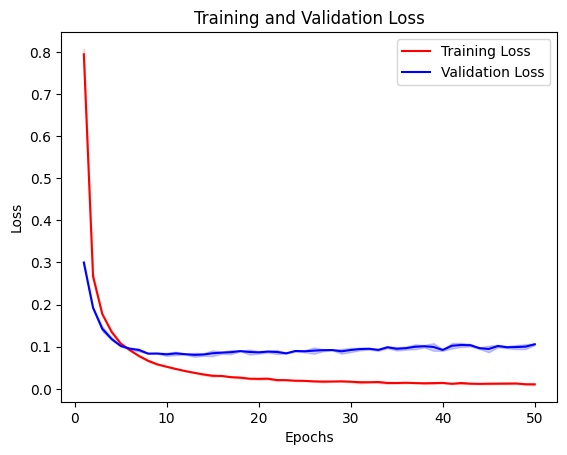

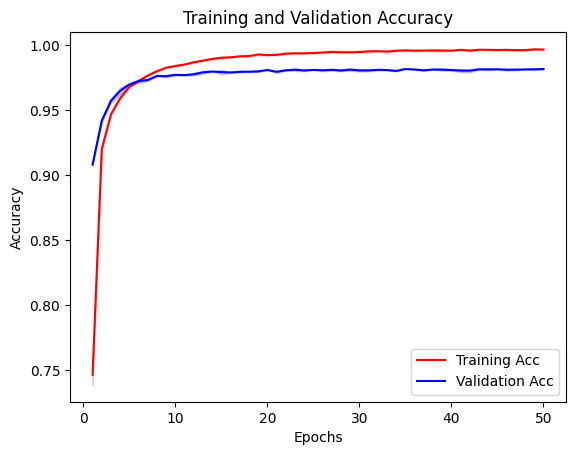

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# collect all histories
all_train_loss = np.array([h['train_loss'] for h in all_histories])
all_val_loss = np.array([h['val_loss'] for h in all_histories])
all_train_acc = np.array([h['train_acc'] for h in all_histories])
all_val_acc = np.array([h['val_acc'] for h in all_histories])

epochs = np.arange(1, NUM_EPOCHS + 1)

plt.figure()
plt.plot(epochs, all_train_loss.mean(axis=0), label='Training Loss', color='red')
plt.fill_between(epochs,
                 all_train_loss.mean(axis=0) - all_train_loss.std(axis=0),
                 all_train_loss.mean(axis=0) + all_train_loss.std(axis=0),
                 alpha=0.2, color='red')
plt.plot(epochs, all_val_loss.mean(axis=0), label='Validation Loss', color='blue')
plt.fill_between(epochs,
                 all_val_loss.mean(axis=0) - all_val_loss.std(axis=0),
                 all_val_loss.mean(axis=0) + all_val_loss.std(axis=0),
                 alpha=0.2, color='blue')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

plt.figure()
plt.plot(epochs, all_train_acc.mean(axis=0), label='Training Acc', color='red')
plt.fill_between(epochs,
                 all_train_acc.mean(axis=0) - all_train_acc.std(axis=0),
                 all_train_acc.mean(axis=0) + all_train_acc.std(axis=0),
                 alpha=0.2, color='red')
plt.plot(epochs, all_val_acc.mean(axis=0), label='Validation Acc', color='blue')
plt.fill_between(epochs,
                 all_val_acc.mean(axis=0) - all_val_acc.std(axis=0),
                 all_val_acc.mean(axis=0) + all_val_acc.std(axis=0),
                 alpha=0.2, color='blue')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Shaded region shows the variance, wider = more variance

In [ ]:
def warmup_gpu(model, dataloader, num_batches=5):
    model.eval()
    with torch.no_grad():
        for i, (batch, _) in enumerate(dataloader):
            if i >= num_batches:
                break
            batch = batch.to(device)
            _ = model(batch)
    torch.cuda.synchronize()
    print(f"GPU warmup complete ({num_batches} batches)")




In [ ]:
# NUM_EVAL_RUNS = 3

eval_times_baseline = []
eval_losses_baseline = []
eval_accs_baseline = []
eval_latencies_baseline = []
eval_throughputs_baseline = []

for run in range(NUM_RUNS):
    baseline_model = BaselineModel().to(device)
    baseline_model.load_state_dict(torch.load(f'/content/baseline_run{run}.pth'))
    baseline_model.eval()

    if run == 0:
        warmup_gpu(baseline_model, test_loader)

    test_loss = 0
    test_correct_predictions = 0
    test_total = 0

    torch.cuda.synchronize()
    start = time.time()

    with torch.no_grad():
        for batch, labels in tqdm(test_loader, desc=f'Baseline Testing run {run+1}/{NUM_RUNS}'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            output = baseline_model(batch)
            loss = loss_fn(output, labels)

            test_loss += loss.item()
            predictions = torch.argmax(output, dim=1)
            test_correct_predictions += (predictions == labels).sum().item()
            test_total += len(labels)

    torch.cuda.synchronize()
    end = time.time()

    run_time = end - start
    eval_times_baseline.append(run_time)
    eval_losses_baseline.append(test_loss / len(test_loader))
    eval_accs_baseline.append(test_correct_predictions / test_total)
    eval_latencies_baseline.append(run_time / len(test_loader) * 1000)
    eval_throughputs_baseline.append(test_total / run_time)

    print(f"Run {run+1}: Time={run_time:.2f}s, Loss={eval_losses_baseline[-1]:.4f}, Accuracy={eval_accs_baseline[-1]:.4f}, Latency={eval_latencies_baseline[-1]:.2f}ms, Throughput={eval_throughputs_baseline[-1]:.2f} samples/s")

print(f"\n{'='*40}")
print(f"BASELINE INFERENCE SUMMARY ({NUM_RUNS} runs)")
print(f"{'='*40}")
print(f"Time:       {np.mean(eval_times_baseline):.2f}s ± {np.std(eval_times_baseline):.2f}s")
print(f"Loss:       {np.mean(eval_losses_baseline):.4f} ± {np.std(eval_losses_baseline):.4f}")
print(f"Accuracy:   {np.mean(eval_accs_baseline):.4f} ± {np.std(eval_accs_baseline):.4f}")
print(f"Latency:    {np.mean(eval_latencies_baseline):.2f}ms ± {np.std(eval_latencies_baseline):.2f}ms")
print(f"Throughput: {np.mean(eval_throughputs_baseline):.2f} ± {np.std(eval_throughputs_baseline):.2f} samples/s")

GPU warmup complete (5 batches)


Baseline Testing run 1/3: 100%|██████████| 20/20 [00:02<00:00,  9.84it/s]


Run 1: Time=2.03s, Loss=0.0995, Accuracy=0.9823, Latency=101.73ms, Throughput=4914.92 samples/s


Baseline Testing run 2/3: 100%|██████████| 20/20 [00:02<00:00,  9.80it/s]


Run 2: Time=2.04s, Loss=0.0941, Accuracy=0.9834, Latency=102.21ms, Throughput=4892.01 samples/s


Baseline Testing run 3/3: 100%|██████████| 20/20 [00:02<00:00,  9.85it/s]

Run 3: Time=2.03s, Loss=0.0988, Accuracy=0.9821, Latency=101.66ms, Throughput=4918.49 samples/s

BASELINE INFERENCE SUMMARY (3 runs)
Time:       2.04s ± 0.00s
Loss:       0.0975 ± 0.0024
Accuracy:   0.9826 ± 0.0006
Latency:    101.87ms ± 0.24ms
Throughput: 4908.47 ± 11.73 samples/s


In [ ]:
# Bitlinear Testing
from tqdm import tqdm
import numpy as np

# NUM_EPOCHS = 50
# LEARNING_RATE = .001
# NUM_RUNS = 3

def init_weights(m):
    if hasattr(m, 'bias') and m.bias is not None:
        m.bias.data.zero_()
    for param in m.parameters():
        if param.dim() > 1:
            torch.nn.init.normal_(param, mean=0.0, std=0.01)

run_times = []
run_final_accs = []
run_epochs_to_threshold = []
all_histories = []

for run in range(NUM_RUNS):
    set_seed(run)

    print(f"\n{'='*40}")
    print(f"Run {run+1}/{NUM_RUNS}")
    print(f"{'='*40}")

    bitlinear_model = BitLinearModel().to(device)
    bitlinear_model.apply(init_weights)

    loss_fn = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(bitlinear_model.parameters(), lr=LEARNING_RATE)

    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }

    torch.cuda.synchronize()
    start = time.time()

    for i in range(NUM_EPOCHS):
        # Training Phase
        bitlinear_model.train()
        train_loss = 0
        train_correct_predictions = 0
        train_total = 0

        for batch, labels in tqdm(train_loader, desc=f'Epoch {i + 1}/{NUM_EPOCHS} Training'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            output = bitlinear_model(batch)
            optimizer.zero_grad()

            loss = loss_fn(output, labels)
            train_loss += loss.detach()

            loss.backward()
            optimizer.step()

            predictions = torch.argmax(output, dim=1)
            train_correct_predictions += (predictions == labels).sum()
            train_total += len(labels)

        train_loss = train_loss.cpu().item() / len(train_loader)
        train_acc = train_correct_predictions.cpu().item() / train_total

        # Validation Phase
        bitlinear_model.eval()
        val_loss = 0
        val_correct_predictions = 0
        val_total = 0

        with torch.no_grad():
            for batch, labels in tqdm(val_loader, desc=f'Epoch {i + 1}/{NUM_EPOCHS} Validation'):
                batch = batch.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                output = bitlinear_model(batch)
                loss = loss_fn(output, labels)

                val_loss += loss.detach()

                predictions = torch.argmax(output, dim=1)
                val_correct_predictions += (predictions == labels).sum()
                val_total += len(labels)

        val_loss = val_loss.cpu().item() / len(val_loader)
        val_acc = val_correct_predictions.cpu().item() / val_total

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

    torch.cuda.synchronize()
    end = time.time()

    run_times.append(end - start)
    run_final_accs.append(history['val_acc'][-1])
    all_histories.append(history)

    # 90% threshold
    final_acc = history['val_acc'][-1]
    threshold = 0.9 * final_acc
    epochs_to_threshold = NUM_EPOCHS
    for epoch, acc in enumerate(history['val_acc']):
        if acc >= threshold:
            epochs_to_threshold = epoch + 1
            break
    run_epochs_to_threshold.append(epochs_to_threshold)

    print(f"\nRun {run+1} results:")
    print(f"  Time: {run_times[-1]:.2f}s")
    print(f"  Final accuracy: {run_final_accs[-1]:.4f}")
    print(f"  Epochs to 90% threshold: {epochs_to_threshold}")


    torch.save(bitlinear_model.state_dict(), f'/content/unquantized_run{run}.pth')


print(f"\n{'='*40}")
print(f"BITLINEAR SUMMARY ({NUM_RUNS} runs)")
print(f"{'='*40}")
print(f"Training time:           {np.mean(run_times):.2f}s ± {np.std(run_times):.2f}s")
print(f"Final accuracy:          {np.mean(run_final_accs):.4f} ± {np.std(run_final_accs):.4f}")
print(f"Epochs to 90% threshold: {np.mean(run_epochs_to_threshold):.1f} ± {np.std(run_epochs_to_threshold):.1f}")


Run 1/3


Epoch 50/50 Validation: 100%|██████████| 20/20 [00:02<00:00,  9.53it/s]



Run 1 results:
  Time: 649.64s
  Final accuracy: 0.9801
  Epochs to 90% threshold: 1

Run 2/3


Epoch 50/50 Validation: 100%|██████████| 20/20 [00:02<00:00,  9.56it/s]



Run 2 results:
  Time: 647.51s
  Final accuracy: 0.9797
  Epochs to 90% threshold: 1

Run 3/3


Epoch 50/50 Validation: 100%|██████████| 20/20 [00:02<00:00,  9.54it/s]


Run 3 results:
  Time: 650.11s
  Final accuracy: 0.9800
  Epochs to 90% threshold: 1

BITLINEAR SUMMARY (3 runs)
Training time:           649.09s ± 1.13s
Final accuracy:          0.9799 ± 0.0002
Epochs to 90% threshold: 1.0 ± 0.0


In [ ]:
import shutil
import os

# save checkpoints
for run in range(3):
    shutil.copy(f'/content/unquantized_run{run}.pth', f'/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/checkpoints/MNIST/bitblas/unquantized_run{run}.pth')
    print(f"Run {run} saved")

Run 0 saved
Run 1 saved
Run 2 saved


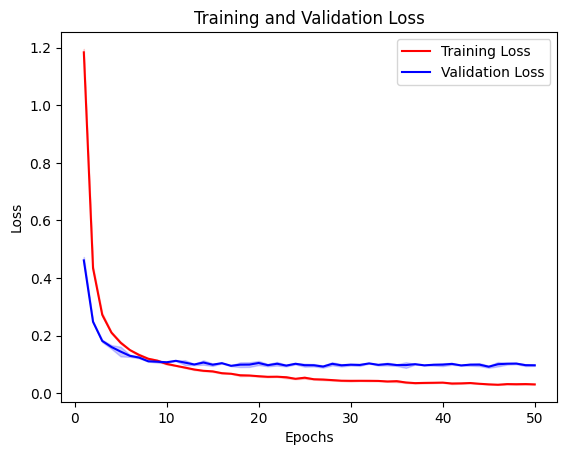

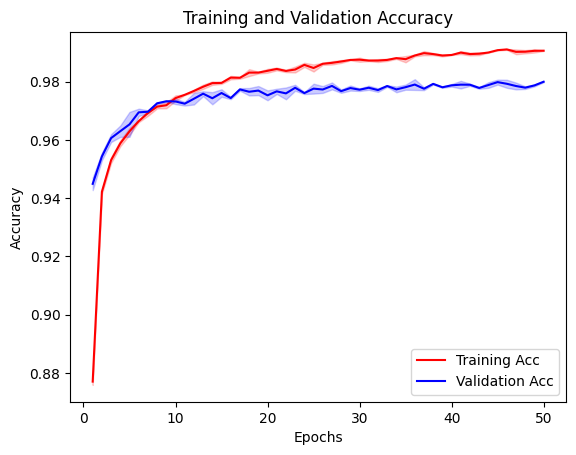

In [ ]:

all_train_loss = np.array([h['train_loss'] for h in all_histories])
all_val_loss = np.array([h['val_loss'] for h in all_histories])
all_train_acc = np.array([h['train_acc'] for h in all_histories])
all_val_acc = np.array([h['val_acc'] for h in all_histories])

epochs = np.arange(1, NUM_EPOCHS + 1)

plt.figure()
plt.plot(epochs, all_train_loss.mean(axis=0), label='Training Loss', color='red')
plt.fill_between(epochs,
                 all_train_loss.mean(axis=0) - all_train_loss.std(axis=0),
                 all_train_loss.mean(axis=0) + all_train_loss.std(axis=0),
                 alpha=0.2, color='red')
plt.plot(epochs, all_val_loss.mean(axis=0), label='Validation Loss', color='blue')
plt.fill_between(epochs,
                 all_val_loss.mean(axis=0) - all_val_loss.std(axis=0),
                 all_val_loss.mean(axis=0) + all_val_loss.std(axis=0),
                 alpha=0.2, color='blue')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

plt.figure()
plt.plot(epochs, all_train_acc.mean(axis=0), label='Training Acc', color='red')
plt.fill_between(epochs,
                 all_train_acc.mean(axis=0) - all_train_acc.std(axis=0),
                 all_train_acc.mean(axis=0) + all_train_acc.std(axis=0),
                 alpha=0.2, color='red')
plt.plot(epochs, all_val_acc.mean(axis=0), label='Validation Acc', color='blue')
plt.fill_between(epochs,
                 all_val_acc.mean(axis=0) - all_val_acc.std(axis=0),
                 all_val_acc.mean(axis=0) + all_val_acc.std(axis=0),
                 alpha=0.2, color='blue')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
eval_times_bitlinear = []
eval_losses_bitlinear = []
eval_accs_bitlinear = []
eval_latencies_bitlinear = []
eval_throughputs_bitlinear = []

for run in range(NUM_RUNS):
    bitlinear_model = BitLinearModel().to(device)
    bitlinear_model.load_state_dict(torch.load(f'/content/unquantized_run{run}.pth'))
    bitlinear_model.eval()

    if run == 0:
        warmup_gpu(bitlinear_model, test_loader)

    test_loss = 0
    test_correct_predictions = 0
    test_total = 0

    torch.cuda.synchronize()
    start = time.time()

    with torch.no_grad():
        for batch, labels in tqdm(test_loader, desc=f'BitLinear Testing run {run+1}/{NUM_RUNS}'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            output = bitlinear_model(batch)
            loss = loss_fn(output, labels)

            test_loss += loss.item()
            predictions = torch.argmax(output, dim=1)
            test_correct_predictions += (predictions == labels).sum().item()
            test_total += len(labels)

    torch.cuda.synchronize()
    end = time.time()

    run_time = end - start
    eval_times_bitlinear.append(run_time)
    eval_losses_bitlinear.append(test_loss / len(test_loader))
    eval_accs_bitlinear.append(test_correct_predictions / test_total)
    eval_latencies_bitlinear.append(run_time / len(test_loader) * 1000)
    eval_throughputs_bitlinear.append(test_total / run_time)

    print(f"Run {run+1}: Time={run_time:.2f}s, Loss={eval_losses_bitlinear[-1]:.4f}, Accuracy={eval_accs_bitlinear[-1]:.4f}, Latency={eval_latencies_bitlinear[-1]:.2f}ms, Throughput={eval_throughputs_bitlinear[-1]:.2f} samples/s")

print(f"\n{'='*40}")
print(f"BITLINEAR INFERENCE SUMMARY ({NUM_RUNS} runs)")
print(f"{'='*40}")
print(f"Time:       {np.mean(eval_times_bitlinear):.2f}s ± {np.std(eval_times_bitlinear):.2f}s")
print(f"Loss:       {np.mean(eval_losses_bitlinear):.4f} ± {np.std(eval_losses_bitlinear):.4f}")
print(f"Accuracy:   {np.mean(eval_accs_bitlinear):.4f} ± {np.std(eval_accs_bitlinear):.4f}")
print(f"Latency:    {np.mean(eval_latencies_bitlinear):.2f}ms ± {np.std(eval_latencies_bitlinear):.2f}ms")
print(f"Throughput: {np.mean(eval_throughputs_bitlinear):.2f} ± {np.std(eval_throughputs_bitlinear):.2f} samples/s")

GPU warmup complete (5 batches)


BitLinear Testing run 1/3: 100%|██████████| 20/20 [00:02<00:00,  9.52it/s]


Run 1: Time=2.10s, Loss=0.1026, Accuracy=0.9787, Latency=105.19ms, Throughput=4753.11 samples/s


BitLinear Testing run 2/3: 100%|██████████| 20/20 [00:02<00:00,  9.71it/s]


Run 2: Time=2.06s, Loss=0.0869, Accuracy=0.9827, Latency=103.06ms, Throughput=4851.39 samples/s


BitLinear Testing run 3/3: 100%|██████████| 20/20 [00:02<00:00,  9.42it/s]

Run 3: Time=2.13s, Loss=0.0998, Accuracy=0.9811, Latency=106.27ms, Throughput=4704.96 samples/s

BITLINEAR INFERENCE SUMMARY (3 runs)
Time:       2.10s ± 0.03s
Loss:       0.0964 ± 0.0068
Accuracy:   0.9808 ± 0.0016
Latency:    104.84ms ± 1.33ms
Throughput: 4769.82 ± 60.94 samples/s


In [ ]:
# quantization


checkpoint_paths = [
    '/content/unquantized_run0.pth',
    '/content/unquantized_run1.pth',
    '/content/unquantized_run2.pth',
]


for run, path in enumerate(checkpoint_paths):
    print(f"Quantizing run {run}...")
    checkpoint = torch.load(path, map_location='cpu', mmap=True)
    int2_res = {}

    for key, value in checkpoint.items():
        if 'weight' in key and value.dim() == 2:
            scale = 1.0 / value.abs().mean().clamp(min=1e-5)
            weight_int8 = (value * scale).round().clamp(-1, 1).to(torch.int8)

            n, k = value.shape
            if (n, k) in bitblas_matmuls:
                ref_matmul = next(iter(bitblas_matmuls[(n, k)].values()))
                weight_transformed = ref_matmul.transform_weight(weight_int8.cuda()).cpu()
            else:
                weight_transformed = weight_int8

            int2_res[key] = weight_transformed
            int2_res[key.replace('weight', 'weight_scale')] = torch.tensor([1.0 / scale])
        else:
            int2_res[key] = value.clone()

    torch.save(int2_res, f'/content/quantized_run{run}.pth')
    print(f"  Saved to quantized_run{run}.pth")

print("All runs quantized")

Quantizing run 0...
  Saved to quantized_run0.pth
Quantizing run 1...
  Saved to quantized_run1.pth
Quantizing run 2...
  Saved to quantized_run2.pth
All runs quantized


In [ ]:
import shutil
import os

# save checkpoints
for run in range(3):
    shutil.copy(f'/content/quantized_run{run}.pth', f'/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/checkpoints/MNIST/bitblas/quantized_run{run}.pth')
    print(f"Run {run} saved")

Run 0 saved
Run 1 saved
Run 2 saved


In [ ]:
# Inference

eval_times_kernel = []
eval_losses_kernel = []
eval_accs_kernel = []
eval_latencies_kernel = []
eval_throughputs_kernel = []

for run in range(NUM_RUNS):
    inference_kernel = InferenceKernel().to(device)
    inference_kernel.load_state_dict(torch.load(f'/content/quantized_run{run}.pth'), strict=False)
    inference_kernel.eval()

    if run == 0:
        warmup_gpu(inference_kernel, test_loader)

    test_loss = 0
    test_correct_predictions = 0
    test_total = 0

    torch.cuda.synchronize()
    start = time.time()

    with torch.no_grad():
        for batch, labels in tqdm(test_loader, desc=f'Kernel Testing run {run+1}/{NUM_RUNS}'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            output = inference_kernel(batch)
            loss = loss_fn(output, labels)

            test_loss += loss.item()
            predictions = torch.argmax(output, dim=1)
            test_correct_predictions += (predictions == labels).sum().item()
            test_total += len(labels)

    torch.cuda.synchronize()
    end = time.time()

    run_time = end - start
    eval_times_kernel.append(run_time)
    eval_losses_kernel.append(test_loss / len(test_loader))
    eval_accs_kernel.append(test_correct_predictions / test_total)
    eval_latencies_kernel.append(run_time / len(test_loader) * 1000)
    eval_throughputs_kernel.append(test_total / run_time)

    print(f"Run {run+1}: Time={run_time:.2f}s, Loss={eval_losses_kernel[-1]:.4f}, Accuracy={eval_accs_kernel[-1]:.4f}, Latency={eval_latencies_kernel[-1]:.2f}ms, Throughput={eval_throughputs_kernel[-1]:.2f} samples/s")

print(f"\n{'='*40}")
print(f"INFERENCE KERNEL SUMMARY ({NUM_RUNS} runs)")
print(f"{'='*40}")
print(f"Time:       {np.mean(eval_times_kernel):.2f}s ± {np.std(eval_times_kernel):.2f}s")
print(f"Loss:       {np.mean(eval_losses_kernel):.4f} ± {np.std(eval_losses_kernel):.4f}")
print(f"Accuracy:   {np.mean(eval_accs_kernel):.4f} ± {np.std(eval_accs_kernel):.4f}")
print(f"Latency:    {np.mean(eval_latencies_kernel):.2f}ms ± {np.std(eval_latencies_kernel):.2f}ms")
print(f"Throughput: {np.mean(eval_throughputs_kernel):.2f} ± {np.std(eval_throughputs_kernel):.2f} samples/s")

GPU warmup complete (5 batches)


Kernel Testing run 1/3: 100%|██████████| 20/20 [00:02<00:00,  9.12it/s]


Run 1: Time=2.20s, Loss=0.1026, Accuracy=0.9787, Latency=109.78ms, Throughput=4554.55 samples/s


Kernel Testing run 2/3: 100%|██████████| 20/20 [00:02<00:00,  9.60it/s]


Run 2: Time=2.08s, Loss=0.0869, Accuracy=0.9826, Latency=104.24ms, Throughput=4796.44 samples/s


Kernel Testing run 3/3: 100%|██████████| 20/20 [00:02<00:00,  9.52it/s]

Run 3: Time=2.10s, Loss=0.0998, Accuracy=0.9811, Latency=105.15ms, Throughput=4755.18 samples/s

INFERENCE KERNEL SUMMARY (3 runs)
Time:       2.13s ± 0.05s
Loss:       0.0964 ± 0.0068
Accuracy:   0.9808 ± 0.0016
Latency:    106.39ms ± 2.43ms
Throughput: 4702.06 ± 105.66 samples/s


In [ ]:
# reference checks

layer_configs = [
    (512, 512, 832, "Layer 1"),
    (512, 256, 512, "Layer 2"),
    (512, 128, 256, "Layer 3"),
    (512, 32, 128, "Layer 4"),
]

for (m, n, k, name) in layer_configs:
    try:
        config = bitblas.MatmulConfig(
            M=m, N=n, K=k,
            A_dtype="int8", W_dtype="int2",
            accum_dtype="int32", out_dtype="float32",
        )
        test = bitblas.Matmul(config=config)
        input_tensor = torch.randint(-128, 127, (m, k), dtype=torch.int8).cuda()
        weight_tensor = torch.randint(-1, 2, (n, k), dtype=torch.int8).cuda()
        weight_transformed = test.transform_weight(weight_tensor)
        bitblas_out = test(input_tensor.contiguous(), weight_transformed.contiguous())
        ref_result = torch.matmul(input_tensor.float(), weight_tensor.float().t())
        max_diff = (bitblas_out.float() - ref_result.float()).abs().max()
        try:
            torch.testing.assert_close(bitblas_out.float(), ref_result.float(), rtol=1e-2, atol=1.0)
            print(f"{name} (M={m}, N={n}, K={k}): ✅ max_diff={max_diff:.4f}")
        except AssertionError:
            print(f"{name} (M={m}, N={n}, K={k}): ❌ max_diff={max_diff:.4f}")
    except Exception as e:
        print(f"{name} (M={m}, N={n}, K={k}): FAILED - {type(e).__name__}")

Layer 1 (M=512, N=512, K=832): ✅ max_diff=0.0000
Layer 2 (M=512, N=256, K=512): ✅ max_diff=0.0000
Layer 3 (M=512, N=128, K=256): ✅ max_diff=0.0000
Layer 4 (M=512, N=32, K=128): ✅ max_diff=0.0000


In [ ]:
def model_stats(model, filepath):
    # parameter count
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    # size on disk
    torch.save(model.state_dict(), filepath)
    size_mb = os.path.getsize(filepath) / 1024**2

    print(f"Total parameters:     {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,}")
    print(f"Size on disk:         {size_mb:.2f} MB")

model_stats(baseline_model, '/content/baseline_run0.pth')
model_stats(bitlinear_model, '/content/unquantized_run0.pth')
model_stats(inference_kernel, '/content/quantized_run0.pth')

Total parameters:     593,920
Trainable parameters: 593,920
Size on disk:         2.27 MB
Total parameters:     593,920
Trainable parameters: 593,920
Size on disk:         2.27 MB
Total parameters:     148,484
Trainable parameters: 0
Size on disk:         0.15 MB
